# 02 · 多物体 Auto-Decoder

前一篇用一个网络表示一个球体。DeepSDF 真正重要的设计，是让同一个神经网络表示多个物体，并通过不同的潜在向量控制物体形状。本篇给每个物体分配潜在编码，让多个物体共用一个解码器，并联合优化网络和编码。

**前置知识**：[SDF 基础与单物体拟合](01_SDF基础与单物体拟合.ipynb)。本篇有独立的导入、模型和数据，无需运行前一篇，也不依赖它的内核状态。

## 0. 环境与设备

在 `deepsdf` 目录打开本篇，按顺序运行。下面导入依赖并固定随机种子。训练结束后，将共享解码器保存到 `artifacts/auto_decoder.pt`，供第三篇加载。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# 固定随机种子，便于复现实验
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 自动选择设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

# 绘图默认参数
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["axes.grid"] = True

PyTorch: 2.14.1
Device: cpu


## 4. Latent Code：用向量表示形状

前面的网络：

    f_theta(x) -> sdf

只能拟合一个物体。

现在改成：

    f_theta(z, x) -> sdf

其中：

- x：三维空间坐标，维度为 3。
- z：物体的潜在编码，维度为 latent_dim。
- theta：所有物体共享的网络参数。

对于不同物体：

    Object A -> z_A
    Object B -> z_B
    Object C -> z_C

改变 z，网络就可以表示不同的几何形状。

在 DeepSDF 中，训练时每个物体都有一个独立的可学习潜在向量。
这些向量与网络参数共同优化。
为了让形状变化更明显，下面用椭球体构造多个形状。其精确欧氏距离一般没有简单的闭式表达式，我们用一个符号正确、零等值面正确的近似 SDF 作为教学标签。


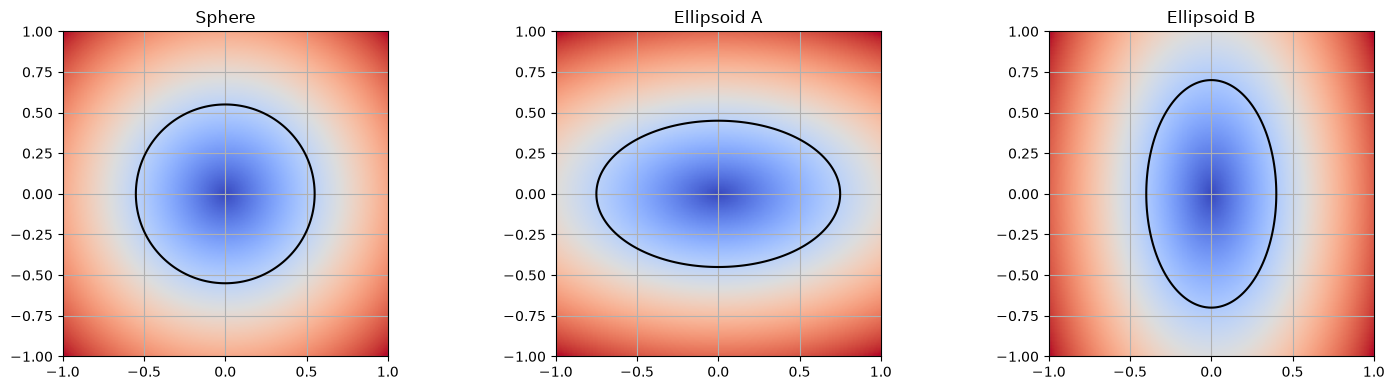

In [3]:
def ellipsoid_sdf_approx(points, radii):
    """
    椭球体的近似 SDF。

    points: (N, 3)
    radii:  (3,)，分别是 x/y/z 方向的半轴长度。

    该公式保证零等值面符合目标椭球，
    但在一般位置上并非精确的欧氏距离。
    """
    radii = torch.as_tensor(
        radii,
        dtype=points.dtype,
        device=points.device,
    )

    normalized_radius = torch.linalg.norm(
        points / radii,
        dim=-1,
        keepdim=True,
    )

    return (normalized_radius - 1.0) * radii.min()


# 比较三个不同形状
shapes = {
    "Sphere":   [0.55, 0.55, 0.55],
    "Ellipsoid A": [0.75, 0.45, 0.55],
    "Ellipsoid B": [0.40, 0.70, 0.50],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axis = torch.linspace(-1, 1, 200)
X, Y = torch.meshgrid(axis, axis, indexing="xy")
plane_points = torch.stack(
    [X.flatten(), Y.flatten(), torch.zeros_like(X).flatten()],
    dim=-1,
)

for ax, (name, radii) in zip(axes, shapes.items()):
    sdf = ellipsoid_sdf_approx(
        plane_points, radii
    ).reshape(200, 200).numpy()

    ax.imshow(
        sdf,
        extent=[-1, 1, -1, 1],
        origin="lower",
        cmap="coolwarm",
    )
    ax.contour(
        X.numpy(), Y.numpy(), sdf,
        levels=[0], colors="black",
    )
    ax.set_title(name)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

现在有多个几何形状需要学习。下一步，我们让网络接收形状编码，并学习所有形状共享的表示。

## 5. Auto-Decoder

DeepSDF 不需要一个编码器直接从输入图像预测潜在向量。

在训练阶段：

1. 为每个训练物体分配一个可学习的 z_i。
2. 将 z_i 和空间坐标 x 拼接。
3. 使用共享 MLP 预测 SDF。
4. 同时更新 MLP 参数和 z_i。

模型：

    f_theta(concat(z_i, x)) -> sdf

训练目标：

    SDF 拟合损失 + 潜在编码正则化

潜在编码是通过优化学习到的，而非由独立编码器直接计算。
下面先为每个形状随机采样坐标，并计算近似 SDF 标签。


In [4]:
# 每个物体使用不同的椭球半轴长度
train_radii = torch.tensor([
    [0.45, 0.45, 0.45],
    [0.60, 0.45, 0.50],
    [0.70, 0.50, 0.40],
    [0.45, 0.65, 0.50],
    [0.50, 0.40, 0.70],
    [0.65, 0.60, 0.45],
    [0.40, 0.55, 0.65],
    [0.70, 0.40, 0.55],
], dtype=torch.float32)

num_shapes = len(train_radii)
points_per_shape = 12_000

all_points = []
all_sdf = []

for radii in train_radii:
    points = torch.rand(points_per_shape, 3) * 2 - 1
    sdf = ellipsoid_sdf_approx(points, radii)

    all_points.append(points)
    all_sdf.append(sdf)

# shape: (num_shapes, points_per_shape, 3)
all_points = torch.stack(all_points)

# shape: (num_shapes, points_per_shape, 1)
all_sdf = torch.stack(all_sdf)

print("Number of shapes:", num_shapes)
print("Points:", all_points.shape)
print("SDF:", all_sdf.shape)

Number of shapes: 8
Points: torch.Size([8, 12000, 3])
SDF: torch.Size([8, 12000, 1])


这里每个物体都有自己的训练样本。`all_points[i]` 和 `all_sdf[i]` 对应第 $i$ 个物体。

## 5.1 定义共享解码器

`nn.Embedding` 是可学习的向量表：每个物体索引对应一个潜在编码；同一个 MLP 接收编码与三维坐标的拼接，输出该物体在该位置的 SDF。


In [5]:
class DeepSDFTeachingModel(nn.Module):
    """
    教学用 Auto-Decoder。

    latent_codes:
        每个训练物体对应一个可学习向量。

    decoder:
        所有物体共享的 SDF 网络。
    """
    def __init__(
        self,
        num_shapes,
        latent_dim=32,
        hidden_dim=128,
    ):
        super().__init__()

        self.latent_dim = latent_dim

        # 每一行对应一个物体的潜在编码
        self.latent_codes = nn.Embedding(
            num_shapes,
            latent_dim,
        )

        nn.init.normal_(
            self.latent_codes.weight,
            mean=0.0,
            std=0.01,
        )

        # 输入是 latent_dim + 3 维
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim + 3, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, 1),
        )

    def forward(self, shape_ids, xyz):
        """
        shape_ids: (N,)
        xyz:       (N, 3)

        输出:
            (N, 1)
        """
        latent = self.latent_codes(shape_ids)
        decoder_input = torch.cat([latent, xyz], dim=-1)

        return self.decoder(decoder_input)


latent_dim = 32
hidden_dim = 128

multi_model = DeepSDFTeachingModel(
    num_shapes=num_shapes,
    latent_dim=latent_dim,
    hidden_dim=hidden_dim,
).to(device)

print(multi_model)

DeepSDFTeachingModel(
  (latent_codes): Embedding(8, 32)
  (decoder): Sequential(
    (0): Linear(in_features=35, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


这里的 `nn.Embedding` 本质上是一个可训练的向量表。输入物体编号，便可取出对应的潜在编码。

## 5.2 联合训练网络和潜在编码

每个批次混合不同物体的采样点，同时优化共享解码器和物体编码。损失由 SDF L1 拟合项与潜在编码 L2 正则项组成。这里的损失是教学简化，不能直接等同于论文的截断 L1 和先验。默认 3000 步，CPU 上可先减少步数和批量。


In [6]:
all_points = all_points.to(device)
all_sdf = all_sdf.to(device)

optimizer = torch.optim.Adam(
    multi_model.parameters(),
    lr=1e-3,
)

num_steps = 3000
batch_size = 4096

# 潜在编码正则化权重
lambda_latent = 1e-3

multi_loss_history = []

multi_model.train()
for step in range(num_steps):
    # 随机选择物体
    shape_ids = torch.randint(
        0, num_shapes, (batch_size,), device=device
    )

    # 每个样本从其所属物体的数据中随机取点
    point_ids = torch.randint(
        0, points_per_shape, (batch_size,), device=device
    )

    xyz_batch = all_points[shape_ids, point_ids]
    sdf_batch = all_sdf[shape_ids, point_ids]

    predicted_sdf = multi_model(shape_ids, xyz_batch)

    # 几何拟合损失
    sdf_loss = F.l1_loss(predicted_sdf, sdf_batch)

    # 当前 batch 中潜在编码的 L2 正则化
    latent_batch = multi_model.latent_codes(shape_ids)
    latent_reg = latent_batch.pow(2).sum(dim=-1).mean()

    loss = sdf_loss + lambda_latent * latent_reg

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    multi_loss_history.append(loss.item())

    if (step + 1) % 300 == 0:
        print(
            f"Step {step + 1:4d}/{num_steps}, "
            f"Total={loss.item():.5f}, "
            f"SDF={sdf_loss.item():.5f}, "
            f"LatentReg={latent_reg.item():.5f}"
        )

Step  300/3000, Total=0.00592, SDF=0.00582, LatentReg=0.10751
Step  600/3000, Total=0.00530, SDF=0.00519, LatentReg=0.10809
Step  900/3000, Total=0.00593, SDF=0.00582, LatentReg=0.10791
Step 1200/3000, Total=0.00540, SDF=0.00530, LatentReg=0.10784
Step 1500/3000, Total=0.00442, SDF=0.00432, LatentReg=0.10773
Step 1800/3000, Total=0.00326, SDF=0.00316, LatentReg=0.10583
Step 2100/3000, Total=0.00392, SDF=0.00382, LatentReg=0.10389
Step 2400/3000, Total=0.00348, SDF=0.00338, LatentReg=0.10371
Step 2700/3000, Total=0.00345, SDF=0.00335, LatentReg=0.10353
Step 3000/3000, Total=0.00352, SDF=0.00341, LatentReg=0.10205


需要注意：这里的正则化是为了讲解 Auto-Decoder 而采用的简化形式。原始 DeepSDF 采用基于潜在向量先验的正则化，并使用截断 L1 损失。两者的具体损失定义和超参数不能直接等同。

## 5.3 查看训练过程

观察总损失曲线和潜在编码表的形状 `(8, 32)`：8 个训练物体各有一个 32 维向量。编码维数不等于几何形状的自由度。


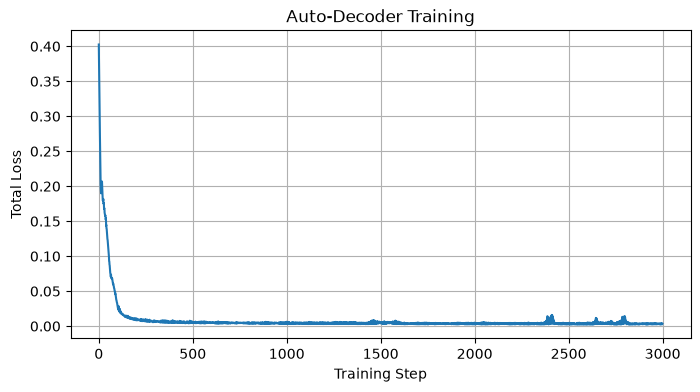

Latent code matrix shape: torch.Size([8, 32])


In [7]:
plt.figure(figsize=(8, 4))
plt.plot(multi_loss_history)
plt.xlabel("Training Step")
plt.ylabel("Total Loss")
plt.title("Auto-Decoder Training")
plt.show()

print(
    "Latent code matrix shape:",
    multi_model.latent_codes.weight.shape,
)

输出的潜在编码矩阵形状是 (8, 32)。这表示目前有 8 个训练物体，每个物体对应一个 32 维向量。

需要注意，潜在编码的维度并不直接等于形状的实际自由度。网络参数和潜在编码共同决定最终的几何表示。

## 5.4 保存共享解码器

第三篇只需要共享解码器，不需要训练物体的潜在编码表。保存解码器权重、结构参数、正则化权重和训练形状的半轴长度，就能在新内核中继续重建实验，无需重新训练。

`artifacts/auto_decoder.pt` 是本地生成的文件，不纳入版本控制。重新运行本单元会覆盖上一份权重。

In [8]:
artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)
checkpoint_path = artifact_dir / "auto_decoder.pt"

torch.save(
    {
        "decoder_state_dict": {
            name: value.detach().cpu()
            for name, value in multi_model.decoder.state_dict().items()
        },
        "latent_dim": latent_dim,
        "hidden_dim": hidden_dim,
        "lambda_latent": lambda_latent,
        "train_radii": train_radii.cpu(),
    },
    checkpoint_path,
)
print("Saved:", checkpoint_path.resolve())

Saved: /Users/scy/Repo/experiments/learnx-from0/deepsdf/artifacts/auto_decoder.pt


## 本篇回顾

训练物体各自拥有一个潜在向量，解码器学习各形状共享的表示；训练时两者一起更新。

下一篇：[新物体潜在编码重建](03_新物体潜在编码重建.ipynb)。保存上面的权重后，可以关闭本篇或重启内核，在第三篇只优化新物体的编码。